In [1]:
print("My Data Cleaning & Reporting Automation Project")
print("Starting the project successfully!")

My Data Cleaning & Reporting Automation Project
Starting the project successfully!


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import pandas as pd

data = {
    "Customer": ["Usha", "Ravi", "Shali", "Sasi", "Hyma",
                 "Sravs", "Chandana", "Nani"],
    "Product": ["Laptop", "Phone", "Tablet", "Laptop",
                "Phone", "Tablet", "Laptop", "Phone"],
    "Sales": [50000, 20000, 50000, 50000, None,
              15000, 45000, -500],
    "Region": ["south", "NORTH", "South", "south",
               "East", "WEST", "North", "east"]
}

df = pd.DataFrame(data)

print("Original Dataset")
display(df)

df.to_csv("messy_sales_data.csv", index=False)

Original Dataset


,Customer,Product,Sales,Region
0,Usha,Laptop,50000.0,south
1,Ravi,Phone,20000.0,NORTH
2,Shali,Tablet,50000.0,South
3,Sasi,Laptop,50000.0,south
4,Hyma,Phone,NaN,East
5,Sravs,Tablet,15000.0,WEST
6,Chandana,Laptop,45000.0,North
7,Nani,Phone,-500.0,east


In [6]:
print("Dataset size:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print("Dataset size:", df.shape)
print(df.duplicated().sum())

Dataset size: (8, 4)

Missing values:
Customer    0
Product     0
Sales       1
Region      0
dtype: int64

Duplicate rows:
Dataset size: (8, 4)
0


In [7]:
# Create a copy of the original dataset
clean_df = df.copy()

# 1. Standardize column names
clean_df.columns = (
    clean_df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# 2. Standardize text values
for col in ["customer", "product", "region"]:
    clean_df[col] = clean_df[col].apply(
        lambda x: x.strip().title() if isinstance(x, str) else x
    )

# 3. Convert Sales to numeric values
clean_df["sales"] = pd.to_numeric(
    clean_df["sales"], errors="coerce"
)

# 4. Replace negative sales with missing values
clean_df.loc[clean_df["sales"] < 0, "sales"] = None

# 5. Fill missing sales with the median
median_sales = clean_df["sales"].median()
clean_df["sales"] = clean_df["sales"].fillna(median_sales)

# 6. Remove duplicate rows, if any
clean_df = clean_df.drop_duplicates()

# 7. Display the cleaned dataset
print("CLEANED DATASET")
display(clean_df)

print("Remaining missing values:")
print(clean_df.isnull().sum())

CLEANED DATASET


,customer,product,sales,region
0,Usha,Laptop,50000.0,South
1,Ravi,Phone,20000.0,North
2,Shali,Tablet,50000.0,South
3,Sasi,Laptop,50000.0,South
4,Hyma,Phone,47500.0,East
5,Sravs,Tablet,15000.0,West
6,Chandana,Laptop,45000.0,North
7,Nani,Phone,47500.0,East


Remaining missing values:
customer    0
product     0
sales       0
region      0
dtype: int64


In [8]:
clean_df.to_csv("cleaned_sales_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [9]:
# Create an automated data cleaning report

report = pd.DataFrame({
    "Metric": [
        "Original Number of Rows",
        "Cleaned Number of Rows",
        "Original Number of Columns",
        "Missing Sales Values Before Cleaning",
        "Missing Values After Cleaning",
        "Negative Sales Values Before Cleaning",
        "Duplicate Rows Before Cleaning",
        "Total Sales After Cleaning"
    ],
    "Value": [
        len(df),
        len(clean_df),
        len(df.columns),
        df["Sales"].isnull().sum(),
        clean_df.isnull().sum().sum(),
        (df["Sales"] < 0).sum(),
        df.duplicated().sum(),
        clean_df["sales"].sum()
    ]
})

print("AUTOMATED DATA CLEANING REPORT")
display(report)

report.to_csv("cleaning_report.csv", index=False)

print("Report saved successfully!")

AUTOMATED DATA CLEANING REPORT


,Metric,Value
0,Original Number of Rows,8.0
1,Cleaned Number of Rows,8.0
2,Original Number of Columns,4.0
3,Missing Sales Values Before Cleaning,1.0
4,Missing Values After Cleaning,0.0
5,Negative Sales Values Before Cleaning,1.0
6,Duplicate Rows Before Cleaning,0.0
7,Total Sales After Cleaning,325000.0


Report saved successfully!


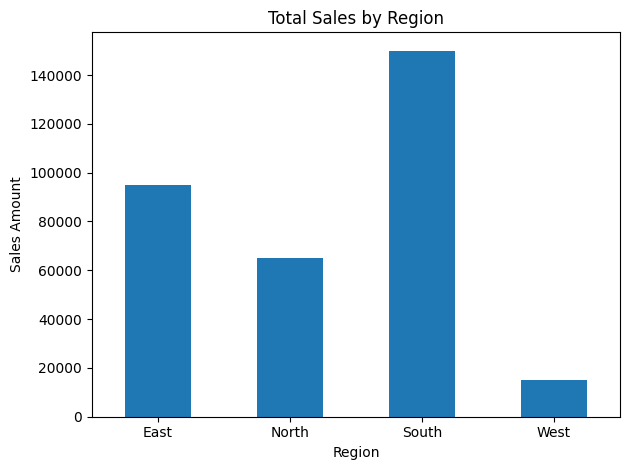

Sales chart created successfully!


In [10]:
import matplotlib.pyplot as plt

sales_by_region = clean_df.groupby("region")["sales"].sum()

sales_by_region.plot(kind="bar")

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales Amount")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("sales_by_region.png")
plt.show()

print("Sales chart created successfully!")

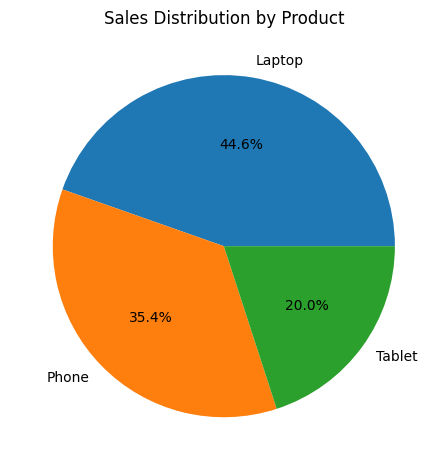

Product sales chart created successfully!


In [11]:
sales_by_product = clean_df.groupby("product")["sales"].sum()

sales_by_product.plot(kind="pie", autopct="%1.1f%%")

plt.title("Sales Distribution by Product")
plt.ylabel("")
plt.tight_layout()

plt.savefig("sales_by_product.png")
plt.show()

print("Product sales chart created successfully!")

In [12]:
import os

print("PROJECT FILES")
for file in os.listdir():
    if file.endswith((".csv", ".png")):
        print("✅", file)

PROJECT FILES
✅ cleaning_report.csv
✅ sales_by_region.png
✅ sales_by_product.png
✅ messy_sales_data.csv
✅ cleaned_sales_data.csv


In [13]:
import shutil

project_files = [
    "messy_sales_data.csv",
    "cleaned_sales_data.csv",
    "cleaning_report.csv",
    "sales_by_region.png",
    "sales_by_product.png"
]

with open("README.txt", "w") as f:
    f.write("""DATA CLEANING & REPORTING AUTOMATION

Objective:
Clean sales data and generate an automated summary report.

Tools:
Python, Pandas, Matplotlib, Google Colab.

Tasks performed:
1. Standardized column names and text values.
2. Handled missing and invalid sales values.
3. Removed duplicate rows.
4. Exported the cleaned dataset.
5. Generated a cleaning report and sales charts.
""")

project_files.append("README.txt")

with shutil.make_archive("Data_Cleaning_Project", "zip", ".", ".") as archive:
    pass

TypeError: 'str' object does not support the context manager protocol

In [14]:
import shutil

project_files = [
    "messy_sales_data.csv",
    "cleaned_sales_data.csv",
    "cleaning_report.csv",
    "sales_by_region.png",
    "sales_by_product.png"
]

with open("README.txt", "w") as f:
    f.write("""DATA CLEANING & REPORTING AUTOMATION

Objective:
Clean sales data and generate an automated summary report.

Tools:
Python, Pandas, Matplotlib, Google Colab.

Tasks performed:
1. Standardized column names and text values.
2. Handled missing and invalid sales values.
3. Removed duplicate rows.
4. Exported the cleaned dataset.
5. Generated a cleaning report and sales charts.
""")

project_files.append("README.txt")

with shutil.make_archive("Data_Cleaning_Project", "zip", ".", ".") as archive:
    pass

TypeError: 'str' object does not support the context manager protocol

In [15]:
with shutil.make_archive("Data_Cleaning_Project", "zip", ".", ".") as archive:
    pass

TypeError: 'str' object does not support the context manager protocol

In [16]:
import zipfile
import os

project_files = [
    "messy_sales_data.csv",
    "cleaned_sales_data.csv",
    "cleaning_report.csv",
    "sales_by_region.png",
    "sales_by_product.png",
    "README.txt"
]

with zipfile.ZipFile("Data_Cleaning_Project.zip", "w") as z:
    for file in project_files:
        if os.path.exists(file):
            z.write(file)

print("Project ZIP created successfully!")

Project ZIP created successfully!


In [17]:
from google.colab import files
files.download("Data_Cleaning_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>